# 01 · Data exploration: MorphSet

Before modelling, what exactly is in the training data? This notebook checks the structure of
MorphSet and finds three facts that shaped every later decision:

1. **Subject ids are not people.** Splits must be made by person, otherwise identity leaks.
2. **Every image has a mirrored copy** with independently detected landmarks: free
   data augmentation, and a direct measure of dlib's landmark noise.
3. **Expressions inflate the usual face-scale estimates.** That motivates normalising the
   features by expression-stable points.

Full scripts: `experiments/01`–`04`. Runtime: about 1 minute.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)
ROOT = Path.cwd() if (Path.cwd() / "examples").is_dir() else Path.cwd().parent  # repo root

from scipy.spatial.distance import cdist

from facial_expression_analysis.constants import MIRROR_PERMUTATION, STABLE_POINTS
from facial_expression_analysis.geometry import procrustes_normalize, shape_scale
from facial_expression_analysis.training.data import load_morphset

## 1. Overview

In [2]:
data = load_morphset()
meta = data.meta
print(
    f"{len(data):,} rows, {(~meta.mirrored).sum():,} distinct images, landmarks {data.landmarks.shape}"
)
overview = (
    meta[~meta.mirrored]
    .groupby("dataset", observed=True)
    .agg(
        images=("filename", "size"),
        subject_ids=("subject", "nunique"),
        persons=("person", "nunique"),
    )
)
overview.index = overview.index.map({"R": "RaFD", "K": "KDEF", "W": "WSEFEP", "F": "FACES"})
overview.loc["total"] = overview.sum()
overview

166,382 rows, 83,191 distinct images, landmarks (166382, 68, 2)


,images,subject_ids,persons
dataset,,,
FACES,31021,341,171
KDEF,19740,140,70
RaFD,28341,201,67
WSEFEP,4089,29,29
total,83191,711,337


In [3]:
step = meta.filename.str.split("_").str[-2]
labels = meta[~meta.mirrored].label.value_counts().rename("images").to_frame().T
print("morph steps per expression:", sorted(step[step != "NE"].astype(int).unique().tolist()))
labels

morph steps per expression: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


label,AN,AN_DI,DI,DI_SA1,DI_SA2,DI_SA3,HA,SA,AF,HA_SU1,HA_SU2,HA_SU3,SU,SU_AF,NE
images,7110,7110,7110,7110,7110,7110,7110,7110,7100,3700,3700,3700,3700,3700,711


Each person's neutral face (`NE`) is morphed in 10 steps towards 7 basic expressions and
4 blends: AN_DI, DI_SA1–3, HA_SU1–3, SU_AF. The blends at three ratios fill the circumplex
between their prototypes.

## 2. The labels

angles covered: 10° to 205°; max |intensity − radius| = 3.3e-16


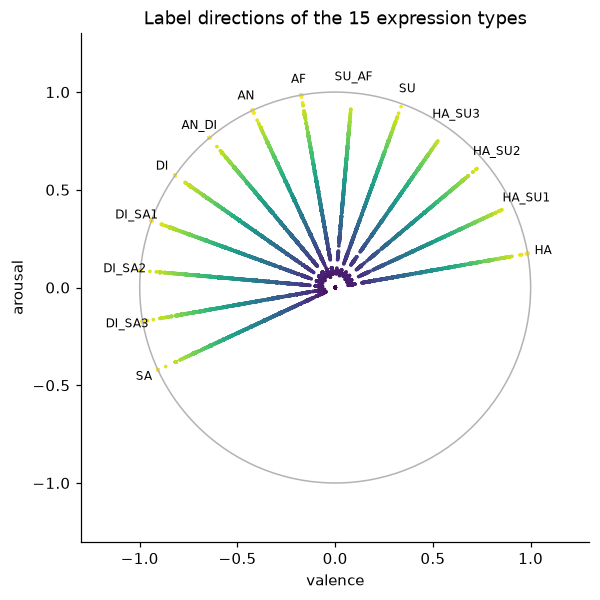

In [4]:
A, V, intensity = data.targets.T
angle = np.degrees(np.arctan2(A, V)) % 360
apex = pd.DataFrame({"label": meta.label.astype(str), "angle": angle, "radius": intensity})
apex = (
    apex[apex.label != "NE"]
    .groupby("label")
    .agg(angle=("angle", "median"), max_radius=("radius", "max"))
)

fig, ax = plt.subplots(figsize=(6.2, 6))
sel = np.random.default_rng(0).choice(len(data), 15_000, replace=False)
ax.scatter(V[sel], A[sel], c=intensity[sel], s=2, cmap="viridis")
for lab, row in apex.iterrows():
    a = np.radians(row.angle)
    ax.annotate(lab, (1.08 * np.cos(a), 1.08 * np.sin(a)), ha="center", va="center", fontsize=8)
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="0.7"))
ax.set(
    xlim=(-1.3, 1.3),
    ylim=(-1.3, 1.3),
    aspect="equal",
    xlabel="valence",
    ylabel="arousal",
    title="Label directions of the 15 expression types",
)
print(
    f"angles covered: {angle[intensity > 0.05].min():.0f}° to {angle[intensity > 0.05].max():.0f}°;",
    f"max |intensity − radius| = {np.abs(intensity - np.hypot(A, V)).max():.1e}",
)

- **Intensity is the radius**, √(A² + V²), for every face.
- **Labels span 10°–205° only.** There are no targets in the calm/relaxed quadrant, so a
  model trained here will rarely predict it (see the model card).

## 3. Subject ids are not people

If every subject id were a different person, a subject's neutral face would be no more similar
to the next id's neutral face than to any other. Below, for every neutral face we find its
nearest neighbour in shape (after Procrustes) and look at the id difference.

In [5]:
ne = meta[(meta.label == "NE") & ~meta.mirrored].drop_duplicates("subject")
shapes = procrustes_normalize(data.landmarks[ne.index.to_numpy()]).reshape(len(ne), -1)
rows = []
for d, name in {"R": "RaFD", "K": "KDEF", "F": "FACES", "W": "WSEFEP"}.items():
    m = (ne.dataset == d).to_numpy()
    D = cdist(shapes[m], shapes[m])
    np.fill_diagonal(D, np.inf)
    nn = D.argmin(1)
    persons = ne.person.to_numpy()[m]
    rows.append(
        {
            "database": name,
            "subject ids": m.sum(),
            "persons": len(set(persons)),
            "nearest neutral face is the same person": (persons[nn] == persons).mean(),
            "chance": 1 / max(m.sum() - 1, 1),
        }
    )
pd.DataFrame(rows).set_index("database")

,subject ids,persons,nearest neutral face is the same person,chance
database,,,,
RaFD,201,67,0.940,0.005
KDEF,140,70,0.864,0.007
FACES,341,171,0.827,0.003
WSEFEP,29,29,0.000,0.036


In RaFD (3 gaze directions per person), KDEF (2 sessions) and FACES (2 picture sets), the
nearest neutral face belongs to the same person 83–94% of the time, against under 1% by chance.
WSEFEP has one photo series per person, so there is no other photo of the same person to find.
The ids are photo series: **711 subject ids are 337 people.** `MorphSet.persons` holds the
corrected ids, and every split in this project uses them.

## 4. Mirrored copies

Every image `…_1.jpg` has a horizontally flipped twin `…_2.jpg`. If the twin's landmarks were
the original's, flipped arithmetically, they would match exactly after flipping back, with the
left/right point labels swapped. They don't: the residual is detector noise, because dlib was
re-run on the flipped image.

83,191 pairs; median residual 1.80 px (1.2% of the inter-ocular distance, median IOD 150 px)


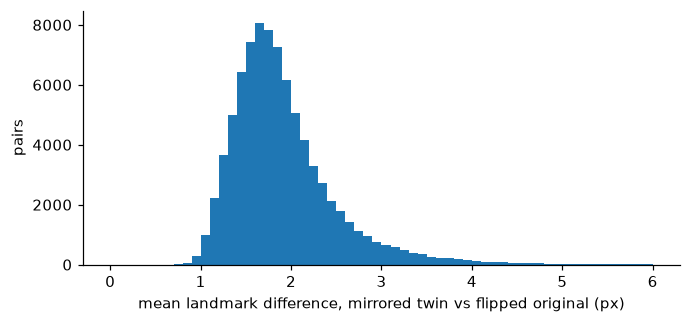

In [6]:
stem = meta.filename.str.replace(r"_[12]\.jpg$", "", regex=True)
first = pd.Series(meta.index[~meta.mirrored], index=stem[~meta.mirrored])
second = pd.Series(meta.index[meta.mirrored], index=stem[meta.mirrored])
pairs = pd.concat([first, second], axis=1, keys=["a", "b"]).dropna().astype(int)
a, b = data.landmarks[pairs.a], data.landmarks[pairs.b]
perm = np.array(MIRROR_PERMUTATION)
flipped = np.stack([-a[:, perm, 0], a[:, perm, 1]], -1)
width = (b[:, :, 0] - flipped[:, :, 0]).mean(1, keepdims=True)  # unknown image width
flipped[:, :, 0] += width
residual = np.linalg.norm(b - flipped, axis=-1).mean(1)
iod = np.linalg.norm(a[:, 36:42].mean(1) - a[:, 42:48].mean(1), axis=1)

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(residual, bins=np.linspace(0, 6, 61))
ax.set(xlabel="mean landmark difference, mirrored twin vs flipped original (px)", ylabel="pairs")
print(
    f"{len(pairs):,} pairs; median residual {np.median(residual):.2f} px "
    f"({np.median(residual / iod):.1%} of the inter-ocular distance, median IOD {np.median(iod):.0f} px)"
)

A median of 1.8 px (≈1.2% of the eye distance) is dlib's repeatability on the same face. This
calibrates the jitter test in notebook 03 (1 px noise per coordinate). Twins share person and
labels, so person-wise splits automatically keep them together.

## 5. Pose and alignment

All MorphSet photos are frontal and eye-aligned. A yaw proxy (horizontal offset of the nose
tip from the eye midpoint, in eye distances) confirms it.

In [7]:
L = data.landmarks
le, re_ = L[:, 36:42].mean(1), L[:, 42:48].mean(1)
eye_dist = np.linalg.norm(re_ - le, axis=1)
yaw_proxy = (L[:, 30, 0] - (le[:, 0] + re_[:, 0]) / 2) / eye_dist
pose = pd.DataFrame({"dataset": meta.dataset, "yaw proxy": yaw_proxy, "eye distance px": eye_dist})
pose.groupby("dataset", observed=True).quantile([0.01, 0.5, 0.99]).unstack()

yaw proxy               eye distance px                  
             0.01   0.50   0.99            0.01     0.50     0.99
dataset                                                          
F          -0.076  0.002  0.081         141.333  150.333  160.182
K          -0.063  0.003  0.073         142.667  150.009  155.506
R          -0.063  0.002  0.070         144.002  149.667  154.834
W          -0.071  0.002  0.075         143.834  149.669  154.837

## 6. Expressions inflate the face scale

Distances must be divided by a face scale. The usual choices (all landmarks, or all non-jaw
landmarks) include the mouth and eyebrows, which move with the expression. For every face we
compute scale(face) / scale(same person's neutral face), which should be 1.

,all 68 landmarks,51 non-jaw (2021),eye centres,stable: nose + eye corners
label,,,,
SU,1.034,1.056,1.002,1.004
HA,1.002,0.994,1.000,0.999
SA,1.004,1.004,0.999,1.012


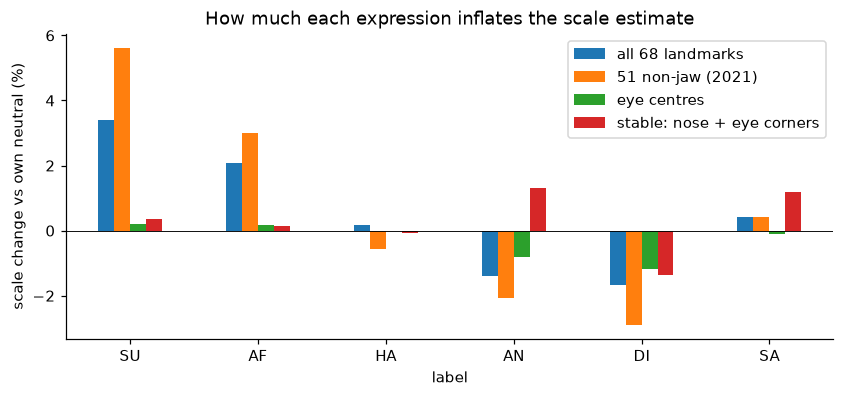

In [8]:
scales = {
    "all 68 landmarks": lambda X: shape_scale(X),
    "51 non-jaw (2021)": lambda X: shape_scale(X[:, 17:]),
    "eye centres": lambda X: np.linalg.norm(X[:, 36:42].mean(1) - X[:, 42:48].mean(1), axis=1),
    "stable: nose + eye corners": lambda X: shape_scale(X[:, list(STABLE_POINTS)]),
}
df = meta[["person", "label"]].copy()
ratios = {}
for name, fn in scales.items():
    df["s"] = fn(L)
    neutral = df[df.label == "NE"].groupby("person").s.mean()
    ratios[name] = (df.s / df.person.map(neutral)).groupby(df.label, observed=True).mean()
ratios = pd.DataFrame(ratios)
ax = ((ratios.loc[["SU", "AF", "HA", "AN", "DI", "SA"]] - 1) * 100).plot.bar(
    figsize=(9, 3.6), rot=0
)
ax.axhline(0, color="k", lw=0.6)
ax.set(
    ylabel="scale change vs own neutral (%)",
    title="How much each expression inflates the scale estimate",
)
ratios.loc[["SU", "HA", "SA"]].round(3)

Surprise (open mouth, raised brows) inflates the non-jaw scale by 5.6%, and fear by 3%,
which shrinks *every* distance feature of those faces. Scales built only on the nose and eye
corners, or on the eye centres, stay within about ±1.4% for every expression. The default
features use the nose and eye corners (13 points, less sensitive to a single noisy landmark
than the 2-point eye distance). In notebook 03 this choice costs a little arousal accuracy: the
inflation itself was a weak arousal cue.

**Next:** notebook 02 removes head pose with frontalization; notebook 03 turns these
findings into features and chooses the model.